In [1]:
#%pip install imbalanced-learn


In [80]:

# 1. Import required libraries
import pandas as pd
import numpy as np
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, roc_auc_score
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [3]:
import os
os.getcwd()
os.chdir(r'C:\Users\raymo\NareshIT_DataScience_AI\IMPORTANT_PROJECTS\2- Customer_churn_prediction_project')

In [4]:
telco_base_data=pd.read_csv(r'Telco-Customer-Churn.csv')

In [5]:
telco_base_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
telco_base_data.shape

(7043, 21)

In [7]:
telco_base_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
telco_base_data.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [9]:
telco_base_data.TotalCharges = pd.to_numeric(telco_base_data.TotalCharges, errors='coerce')

In [10]:
telco_base_data.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [11]:
telco_base_data.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [12]:
cols = [
    'gender',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'SeniorCitizen',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod',
    'Churn'
]

for col in cols:
    print("Column:", col, "- Unique Values:", telco_base_data[col].unique())

Column: gender - Unique Values: ['Female' 'Male']
Column: Partner - Unique Values: ['Yes' 'No']
Column: Dependents - Unique Values: ['No' 'Yes']
Column: PhoneService - Unique Values: ['No' 'Yes']
Column: MultipleLines - Unique Values: ['No phone service' 'No' 'Yes']
Column: SeniorCitizen - Unique Values: [0 1]
Column: InternetService - Unique Values: ['DSL' 'Fiber optic' 'No']
Column: OnlineSecurity - Unique Values: ['No' 'Yes' 'No internet service']
Column: OnlineBackup - Unique Values: ['Yes' 'No' 'No internet service']
Column: DeviceProtection - Unique Values: ['No' 'Yes' 'No internet service']
Column: TechSupport - Unique Values: ['No' 'Yes' 'No internet service']
Column: StreamingTV - Unique Values: ['No' 'Yes' 'No internet service']
Column: StreamingMovies - Unique Values: ['No' 'Yes' 'No internet service']
Column: Contract - Unique Values: ['Month-to-month' 'One year' 'Two year']
Column: PaperlessBilling - Unique Values: ['Yes' 'No']
Column: PaymentMethod - Unique Values: ['Elec

# Missing value Treatment

In [13]:
telco_data=telco_base_data.copy()

In [14]:
telco_data.isnull().sum()/len(telco_data)

customerID          0.000000
gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.001562
Churn               0.000000
dtype: float64

#Since the % of missing records compared to total dataset is very low ie 0.0015%, it is safe to ignore them from further processing.

In [15]:

#Removing missing values

telco_data.dropna(how = 'any', inplace = True)

In [16]:
telco_data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

# EDA


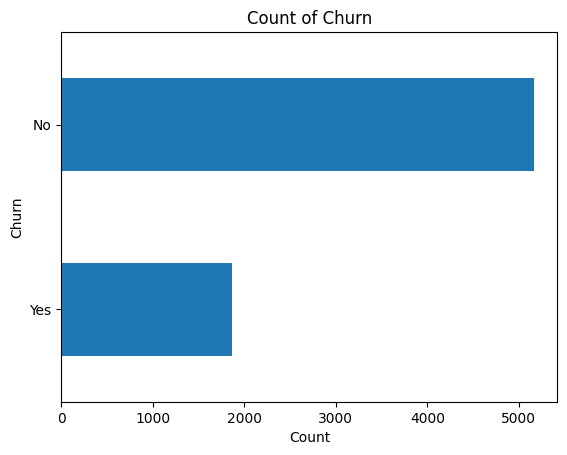

In [17]:
telco_data['Churn'].value_counts().plot(kind='barh')
plt.xlabel("Count")
plt.ylabel("Churn")
plt.title("Count of Churn")
plt.gca().invert_yaxis()  # Invert y-axis to have 'No Churn' on top
plt.show()

In [18]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Convert all the categorical variables into dummy variables


In [19]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()

le

LabelEncoder()

In [20]:
categ=['gender','SeniorCitizen' ,'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod',  'Churn',]

telco_data[categ] = telco_data[categ].apply(le.fit_transform)

In [21]:
telco_data.sample(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
5699,6719-OXYBR,1,0,0,0,15,1,0,1,0,...,2,0,2,0,0,0,2,85.3,1219.85,0
3360,0689-NKYLF,1,0,0,0,13,1,0,1,0,...,2,0,2,0,0,1,2,83.2,1060.60,1
5299,5569-OUICF,0,1,1,0,28,1,2,1,0,...,0,2,2,2,0,1,1,101.3,2812.20,1


In [22]:
#drop column customerID 
telco_data.drop(columns= ['customerID'], axis=1, inplace=True)
telco_data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


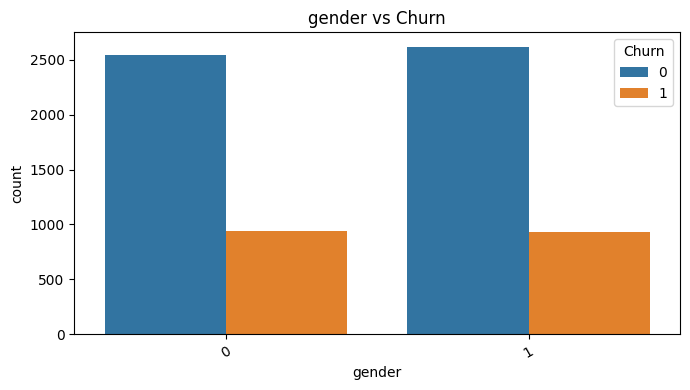

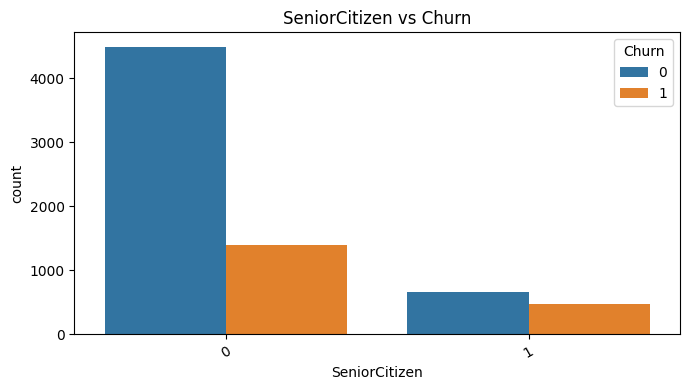

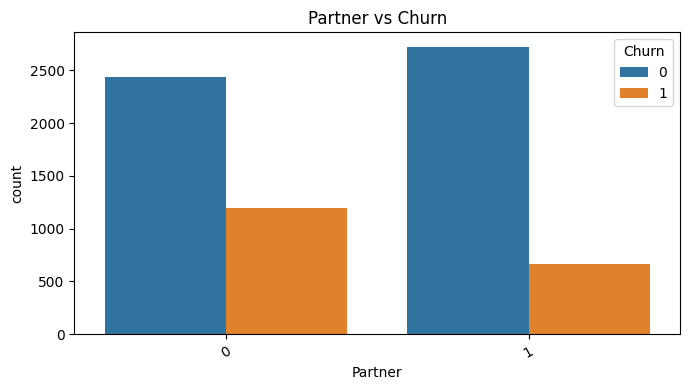

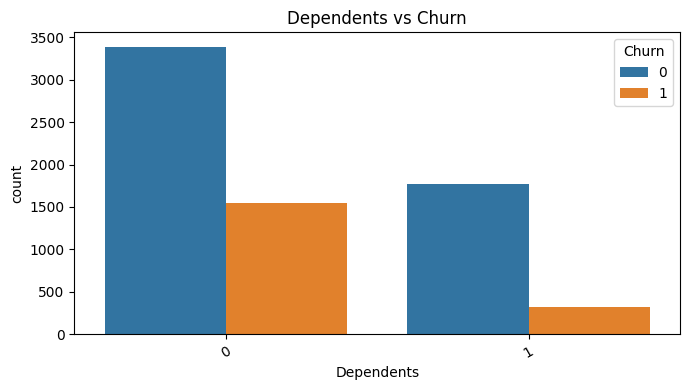

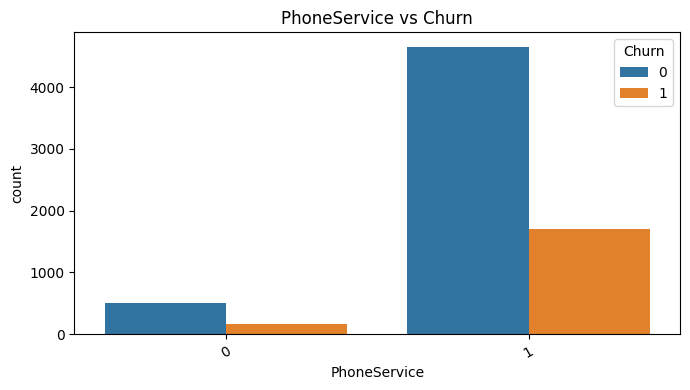

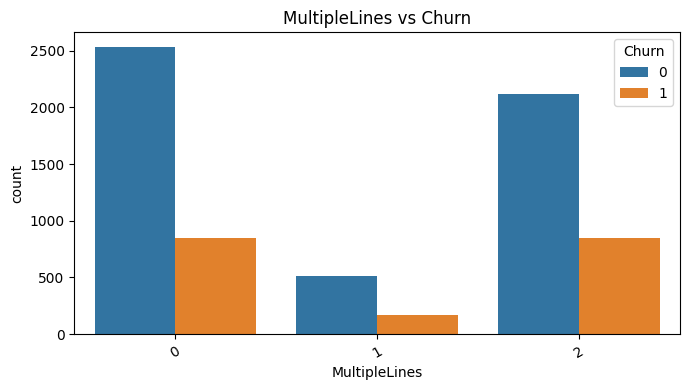

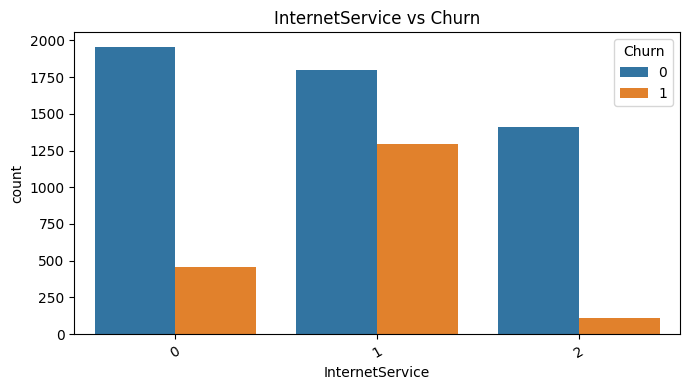

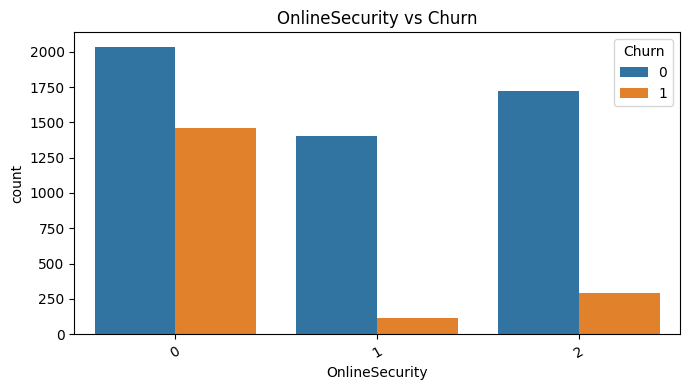

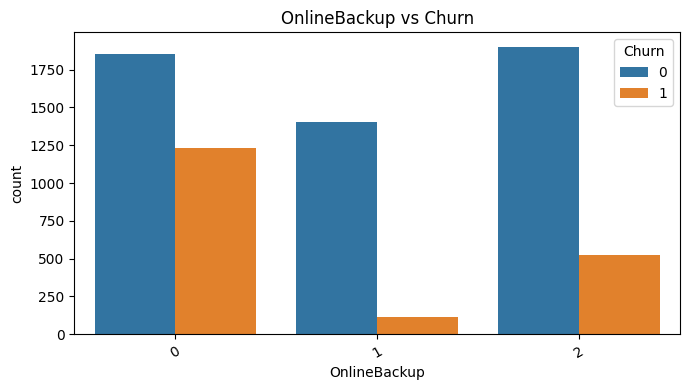

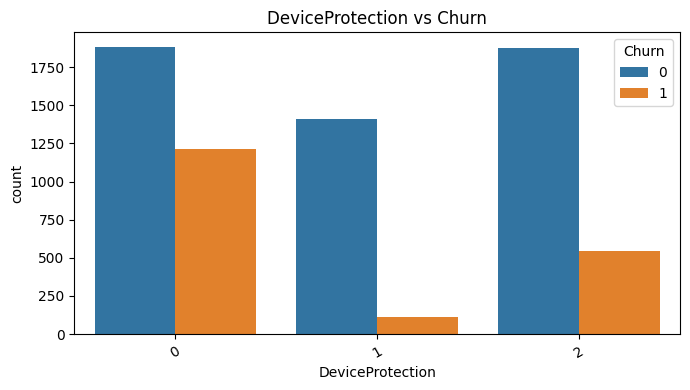

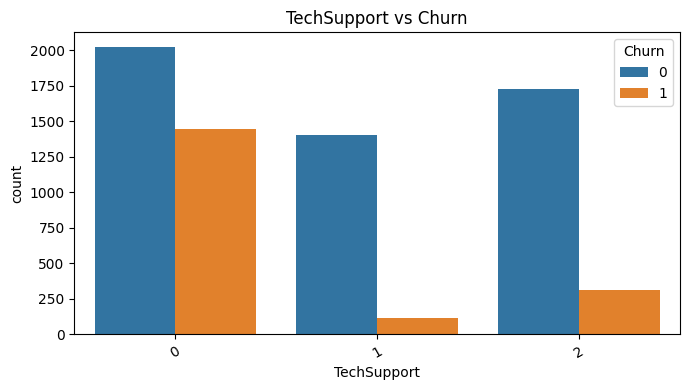

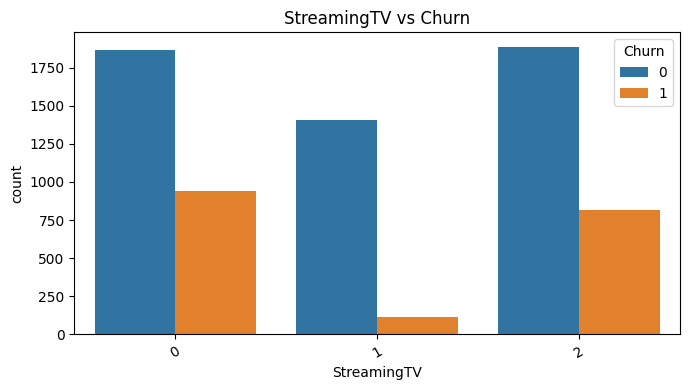

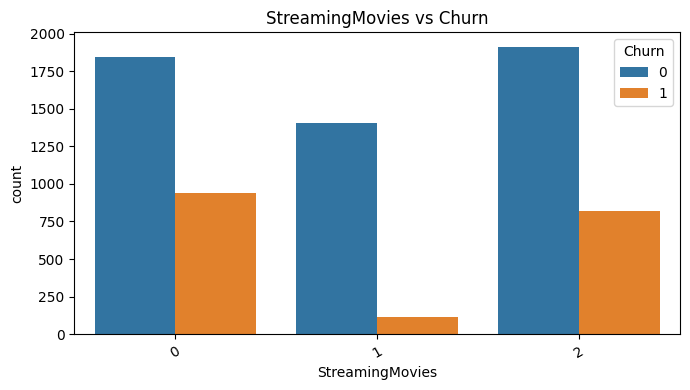

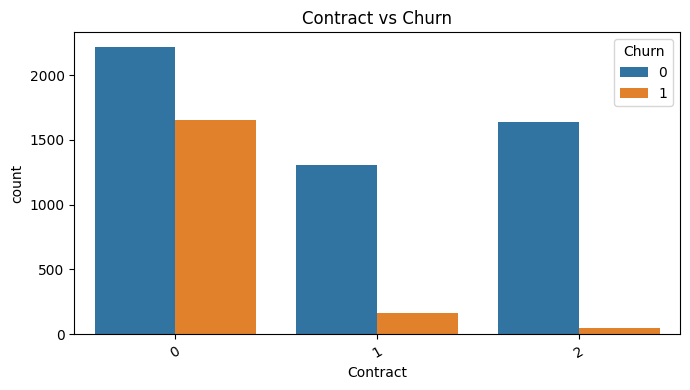

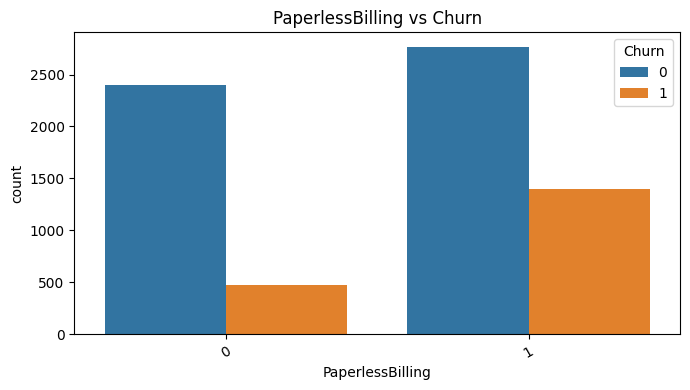

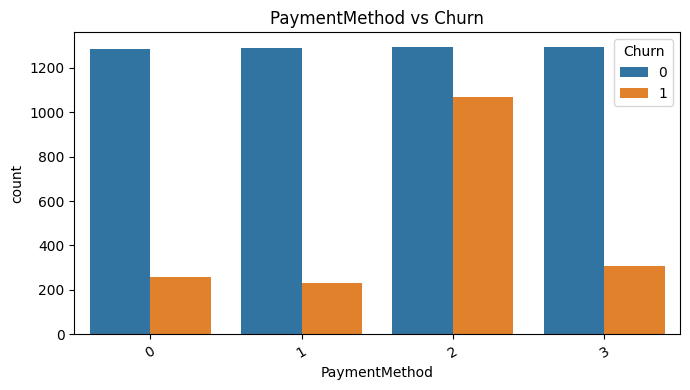

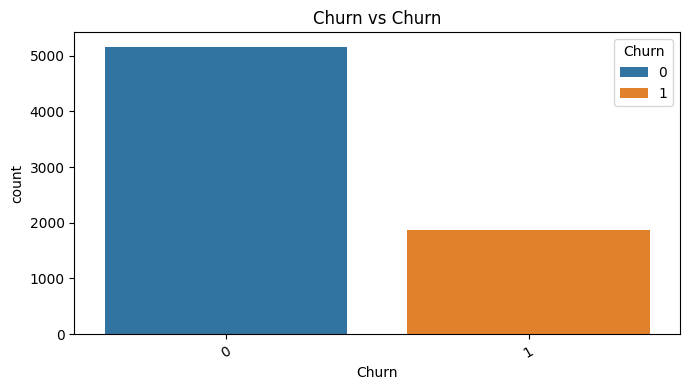

In [23]:
# Countplots for categorical columns

for col in categ:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=telco_data, x=col, hue="Churn")
    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

<Axes: >

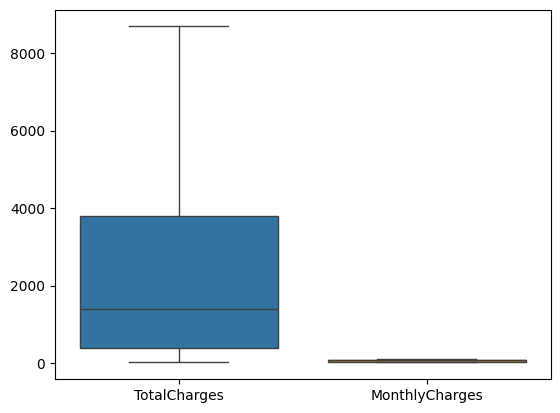

In [24]:
sns.boxplot(data=telco_data[['TotalCharges', 'MonthlyCharges']])

#Relationship between Monthly Charges and Total Charges

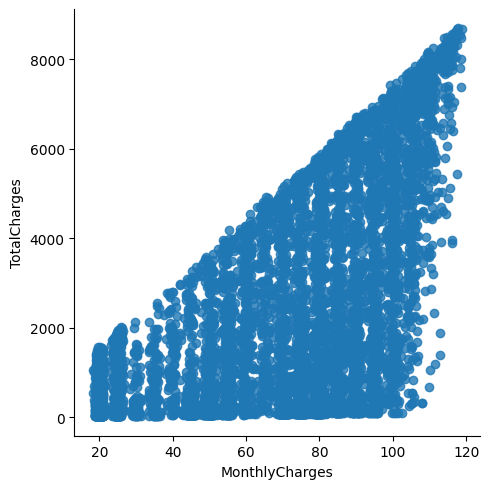

In [25]:
sns.lmplot(data=telco_data, x='MonthlyCharges', y='TotalCharges', fit_reg=False)

#Churn by Monthly Charges and Total Charges

C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\1779507609.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Mth = sns.kdeplot(telco_data.MonthlyCharges[(telco_data["Churn"] == 0) ],
C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\1779507609.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Mth = sns.kdeplot(telco_data.MonthlyCharges[(telco_data["Churn"] == 1) ],


Text(0.5, 1.0, 'Monthly charges by churn')

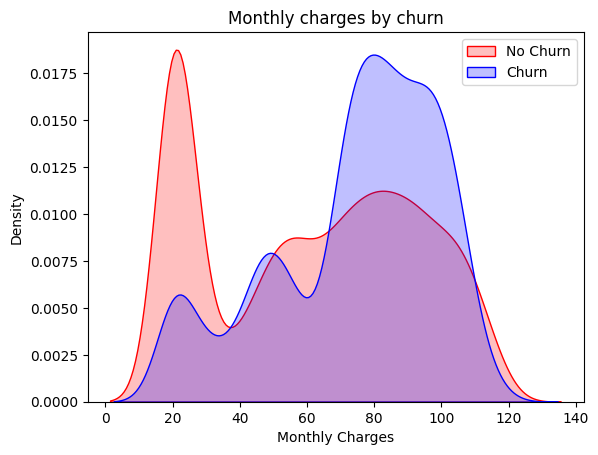

In [26]:
# kernel density estimate (KDE) plot.

Mth = sns.kdeplot(telco_data.MonthlyCharges[(telco_data["Churn"] == 0) ],
                color="Red", shade = True)
Mth = sns.kdeplot(telco_data.MonthlyCharges[(telco_data["Churn"] == 1) ],
                ax =Mth, color="Blue", shade= True)
Mth.legend(["No Churn","Churn"],loc='upper right')
Mth.set_ylabel('Density')
Mth.set_xlabel('Monthly Charges')
Mth.set_title('Monthly charges by churn')

#Insight: Churn is high when Monthly Charges are high

C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\2039743036.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Tot = sns.kdeplot(telco_data.TotalCharges[(telco_data["Churn"] == 0) ],
C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\2039743036.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Tot = sns.kdeplot(telco_data.TotalCharges[(telco_data["Churn"] == 1) ],


Text(0.5, 1.0, 'Total charges by churn')

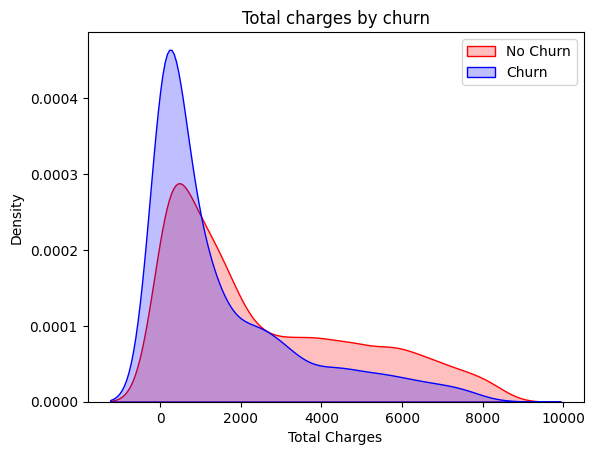

In [27]:
Tot = sns.kdeplot(telco_data.TotalCharges[(telco_data["Churn"] == 0) ],
                color="Red", shade = True)
Tot = sns.kdeplot(telco_data.TotalCharges[(telco_data["Churn"] == 1) ],
                ax =Tot, color="Blue", shade= True)
Tot.legend(["No Churn","Churn"],loc='upper right')
Tot.set_ylabel('Density')
Tot.set_xlabel('Total Charges')
Tot.set_title('Total charges by churn')

#Insight: Churned customers are concentrated at lower total charges, while customers who stayed show a broader distribution with higher total charges.

C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\573088128.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Ten = sns.kdeplot(telco_data.tenure[telco_data["Churn"] == 0],color="Red",shade=True)
C:\Users\raymo\AppData\Local\Temp\ipykernel_22128\573088128.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Ten = sns.kdeplot(telco_data.tenure[telco_data["Churn"] == 1],ax=Ten,color="Blue",shade=True)


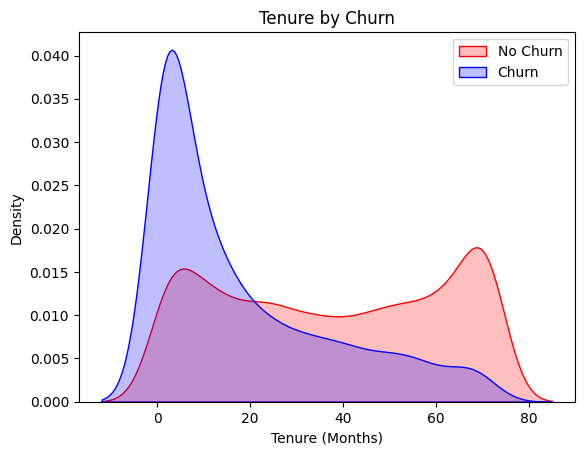

In [28]:
Ten = sns.kdeplot(telco_data.tenure[telco_data["Churn"] == 0],color="Red",shade=True)

Ten = sns.kdeplot(telco_data.tenure[telco_data["Churn"] == 1],ax=Ten,color="Blue",shade=True)

Ten.legend(["No Churn", "Churn"], loc="upper right")
Ten.set_ylabel("Density")
Ten.set_xlabel("Tenure (Months)")
Ten.set_title("Tenure by Churn")

plt.show()

#Insight: Customer churn is concentrated among newer customers, whereas customers with longer tenure are more commonly represented among those who stay.

# Build a corelation of all predictors with 'Churn' 

<Axes: >

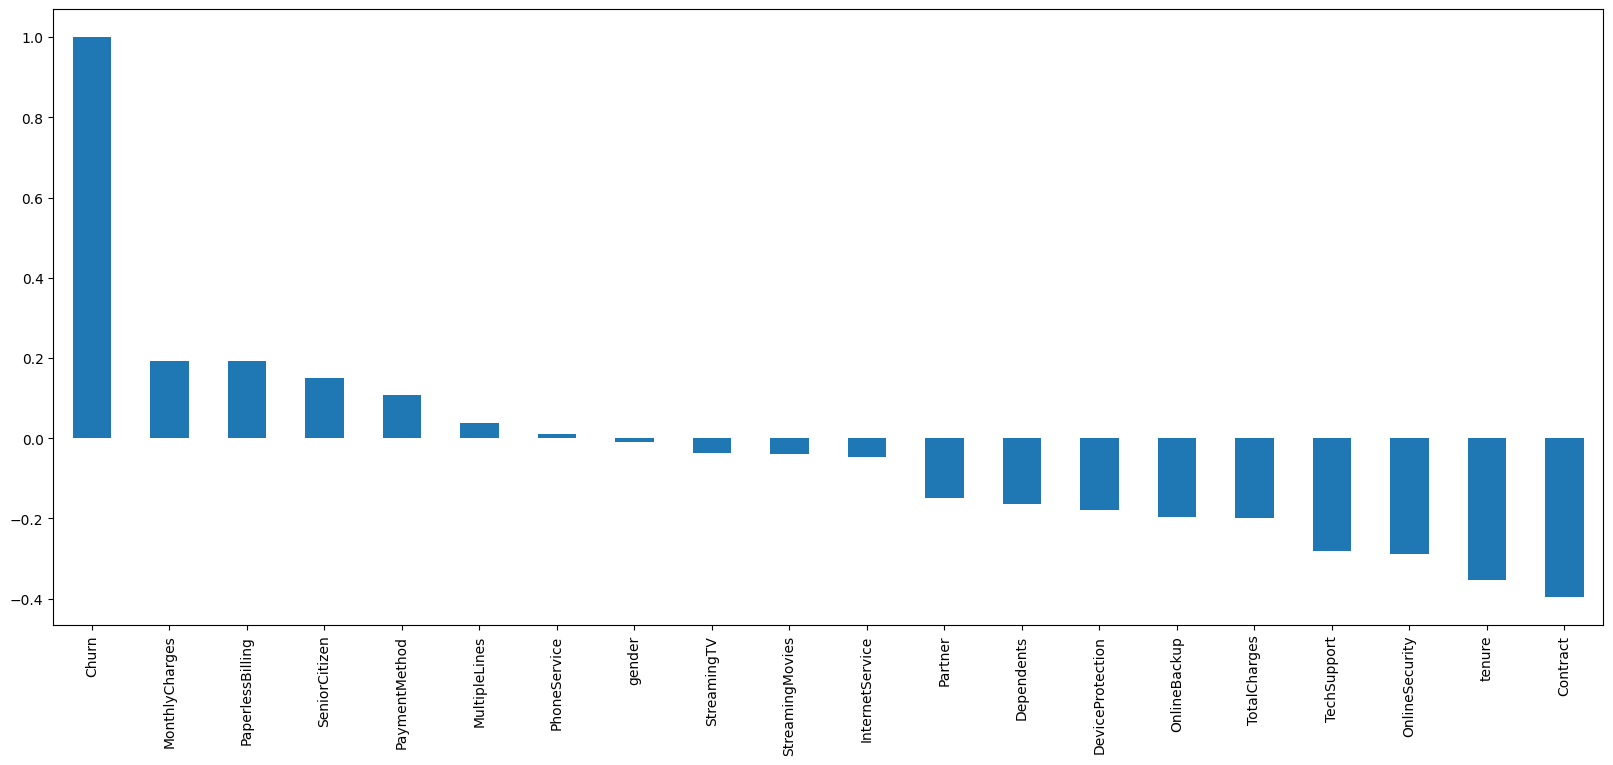

In [29]:
plt.figure(figsize=(20,8))

telco_data.corr()['Churn'].sort_values(ascending = False).plot(kind='bar')

#contract type and tenure had the strongest negative correlations with churn, at approximately -0.39 and -0.35, respectively. This suggests that customers with longer-term contracts and longer tenure tend to be less likely to churn.
Online security and technical support also showed negative relationships with churn.

On the other hand, monthly charges and paperless billing showed positive relationships, suggesting that these features are associated with higher churn.

Gender and phone service had correlations close to zero, indicating very weak linear relationships.

<Axes: >

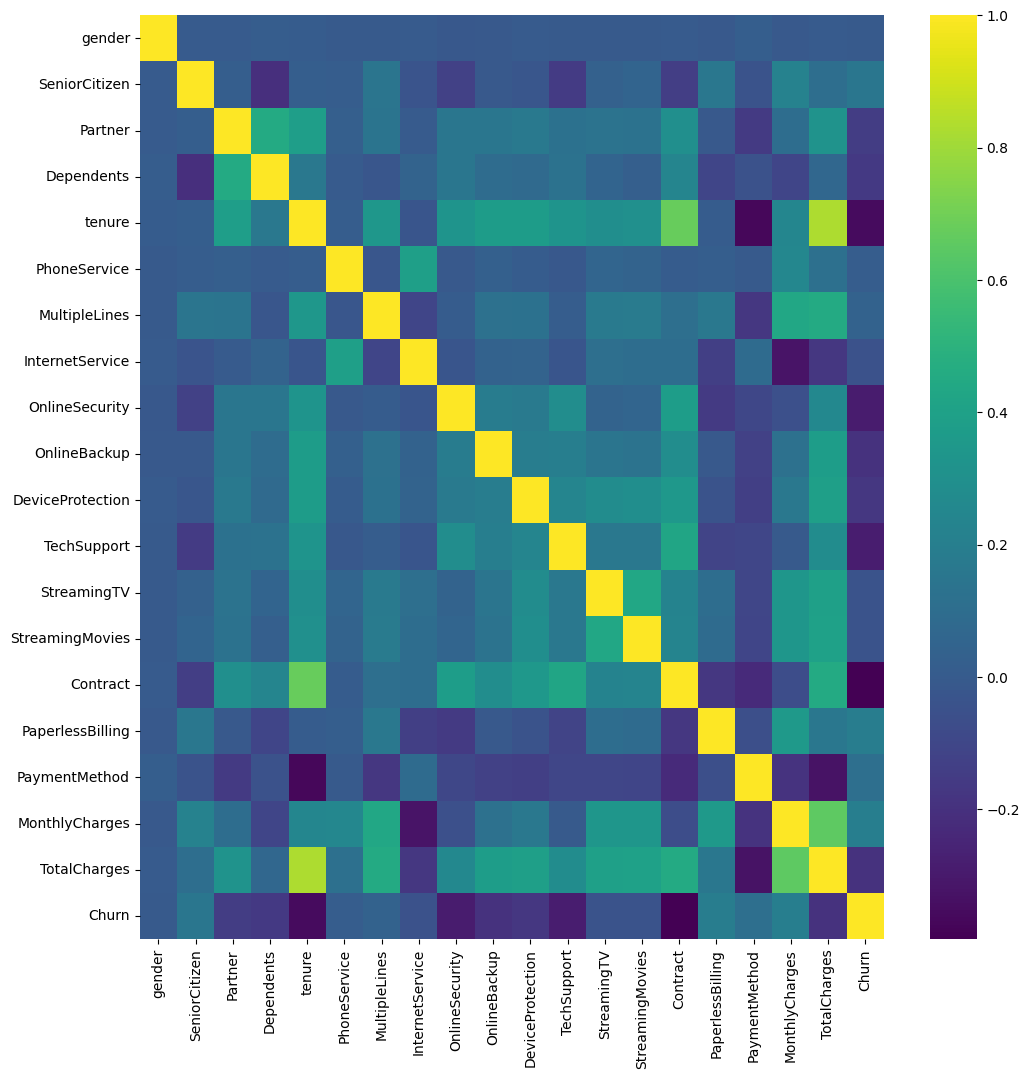

In [30]:
plt.figure(figsize=(12,12))
sns.heatmap(telco_data.corr(), cmap="viridis")

# Bivariate Analysis

In [31]:
new_df1_target0=telco_data.loc[telco_data["Churn"]==0]
new_df1_target1=telco_data.loc[telco_data["Churn"]==1]

In [32]:
def uniplot(df, col, title, hue=None):

    sns.set_style('whitegrid')
    sns.set_context('talk')

    plt.rcParams["axes.labelsize"] = 20
    plt.rcParams['axes.titlesize'] = 22
    plt.rcParams['axes.titlepad'] = 30

    fig, ax = plt.subplots()

    width = len(df[col].unique()) + 7

    if hue is not None:
        width += 4 * len(df[hue].unique())

    fig.set_size_inches(width, 8)

    plt.xticks(rotation=45)
    plt.ylabel('Customer count')
    plt.title(title)

    ax = sns.countplot(data=df,x=col,order=df[col].value_counts().index,hue=hue,palette='bright')
    plt.tight_layout()
    plt.show()

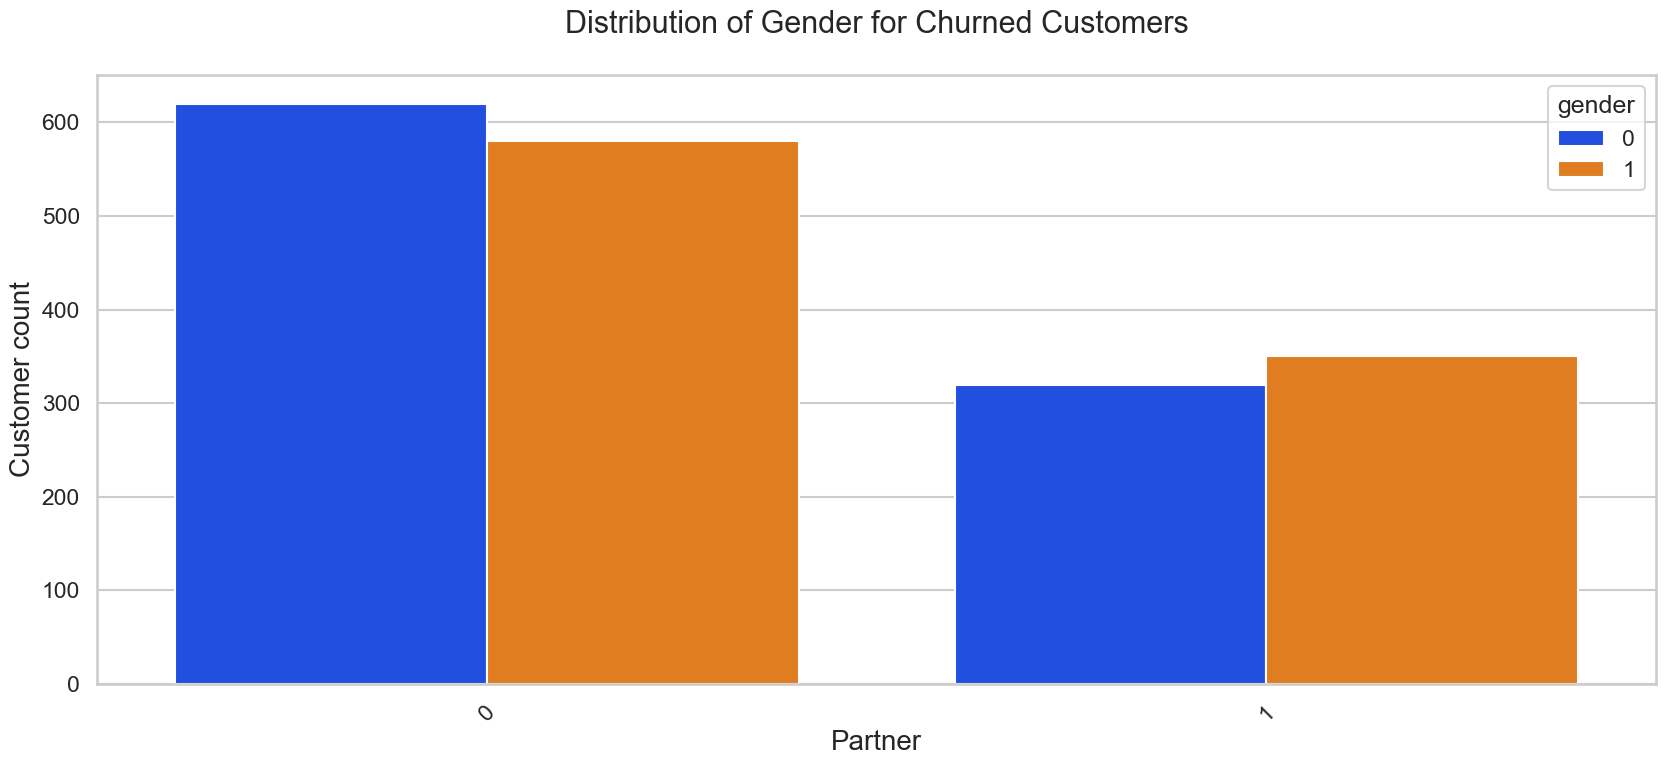

In [33]:
uniplot(new_df1_target1,col='Partner',title='Distribution of Gender for Churned Customers',hue='gender')

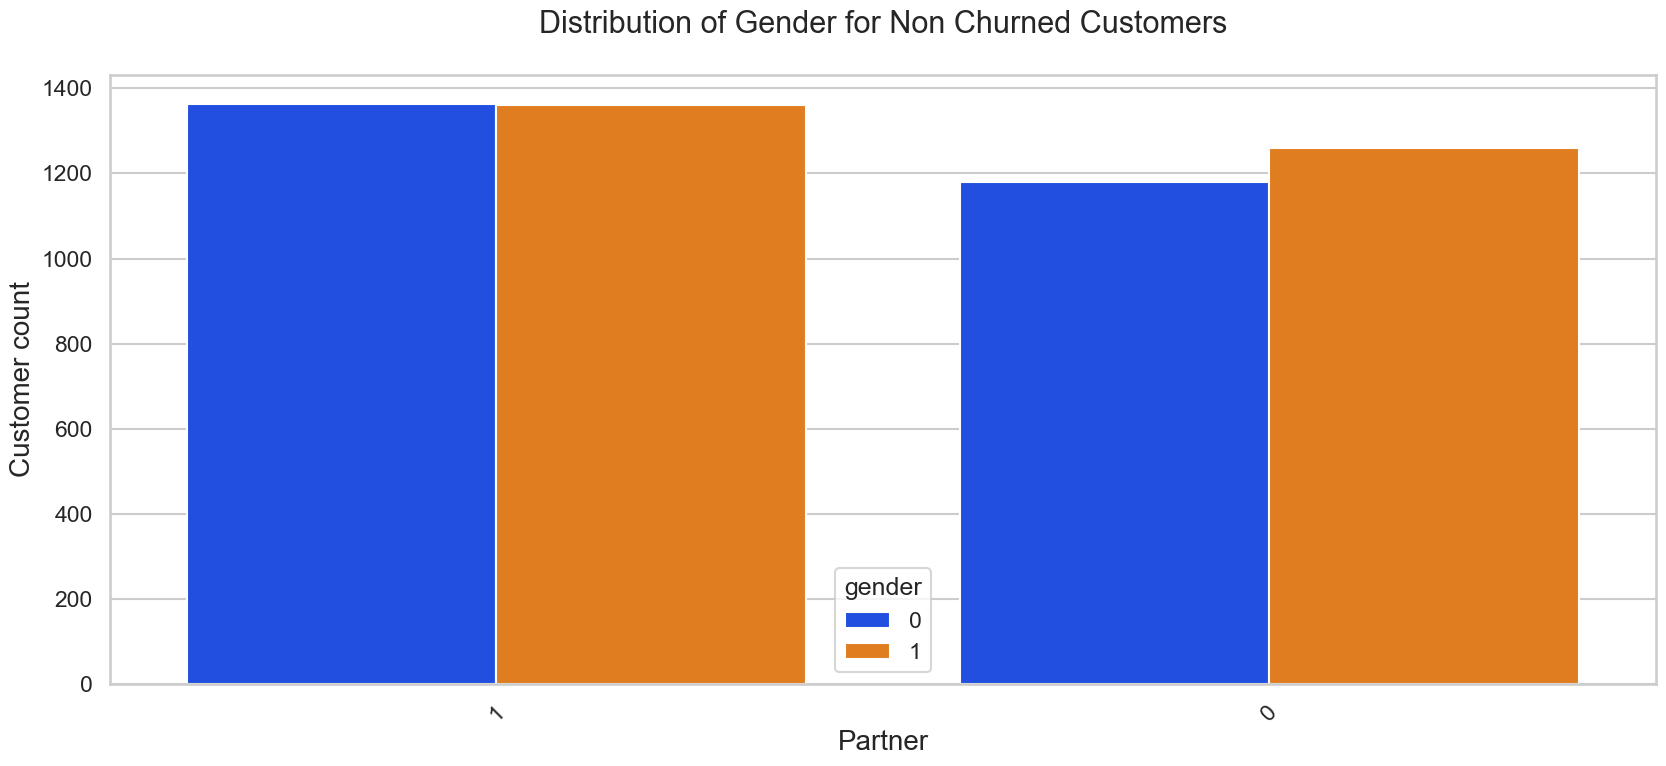

In [34]:
uniplot(new_df1_target0,col='Partner',title='Distribution of Gender for Non Churned Customers',hue='gender')

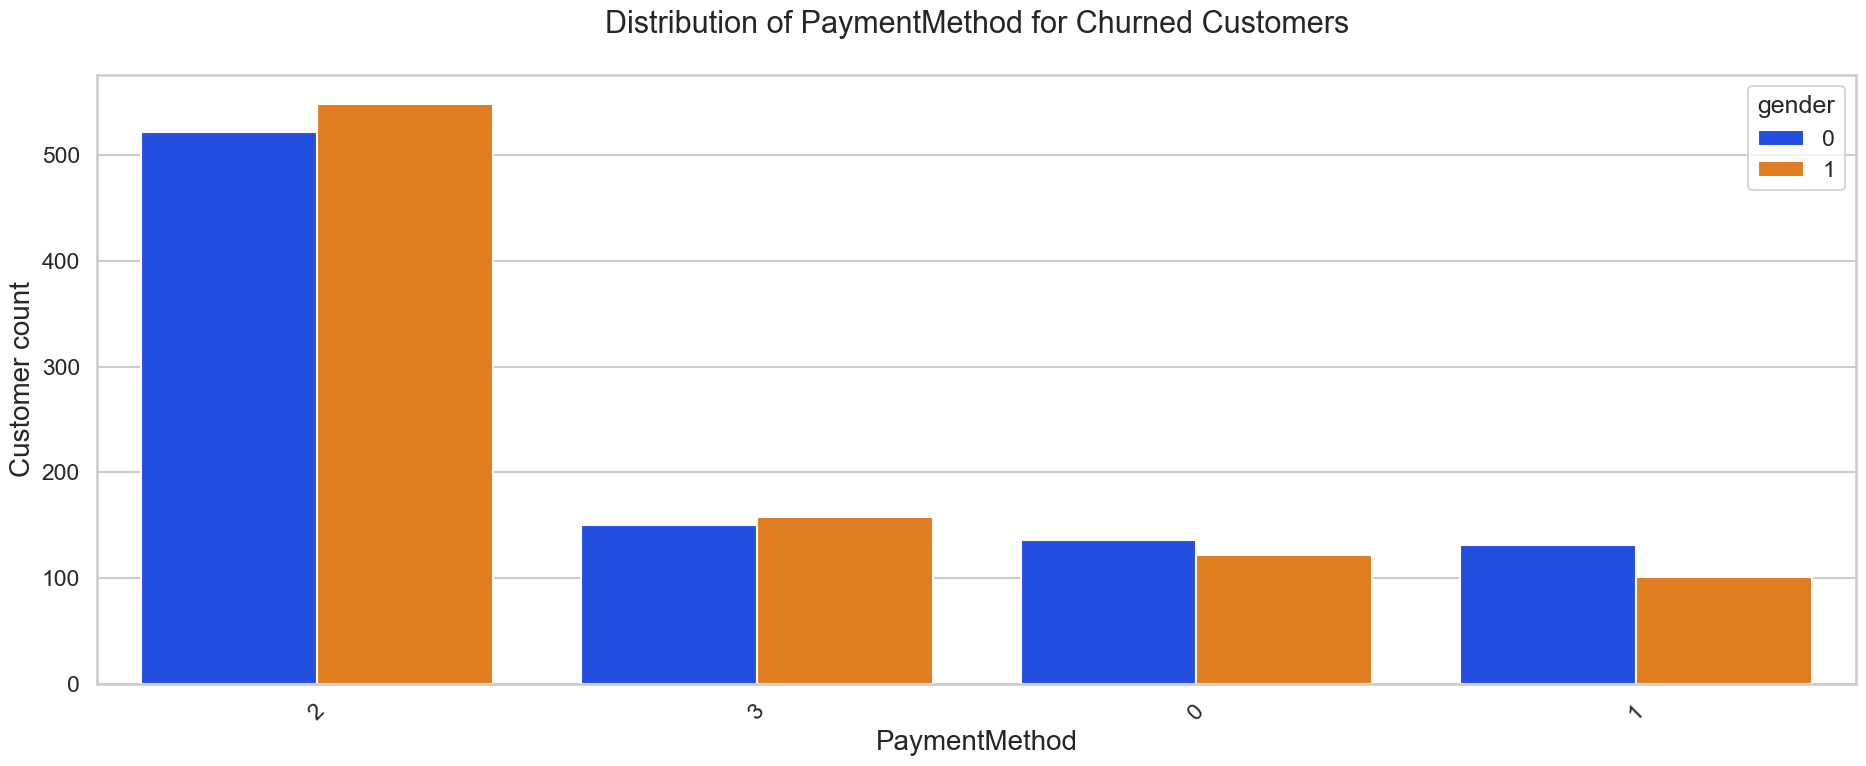

In [35]:
uniplot(new_df1_target1,col='PaymentMethod',title='Distribution of PaymentMethod for Churned Customers',hue='gender')

In [36]:
print(telco_base_data['PaymentMethod'].value_counts())

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


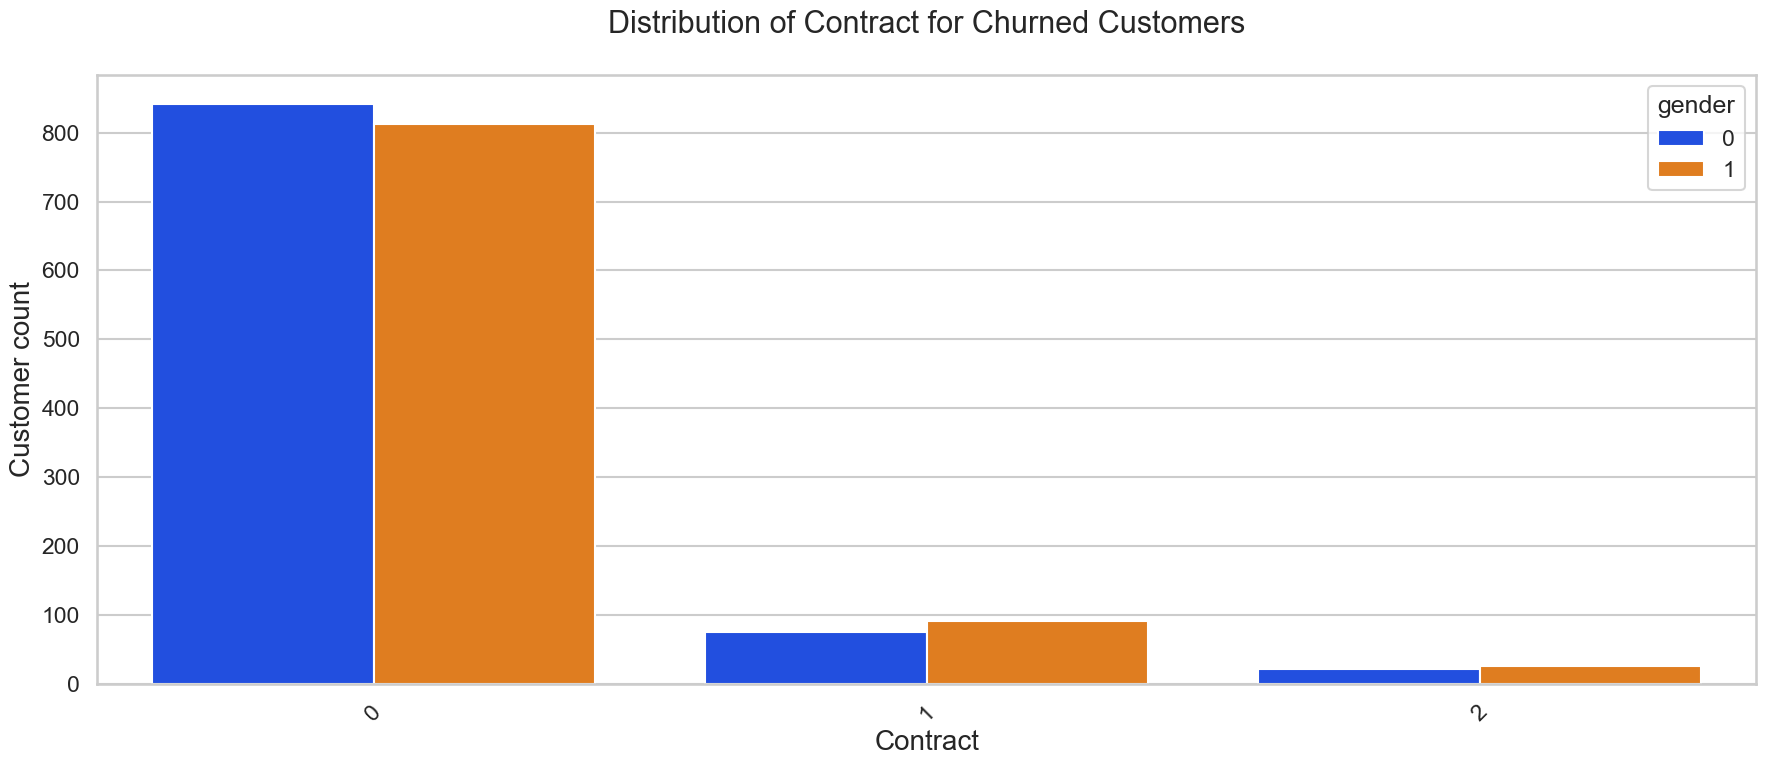

In [37]:
uniplot(new_df1_target1,col='Contract',title='Distribution of Contract for Churned Customers',hue='gender')

In [38]:
print(telco_base_data['Contract'].value_counts())

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


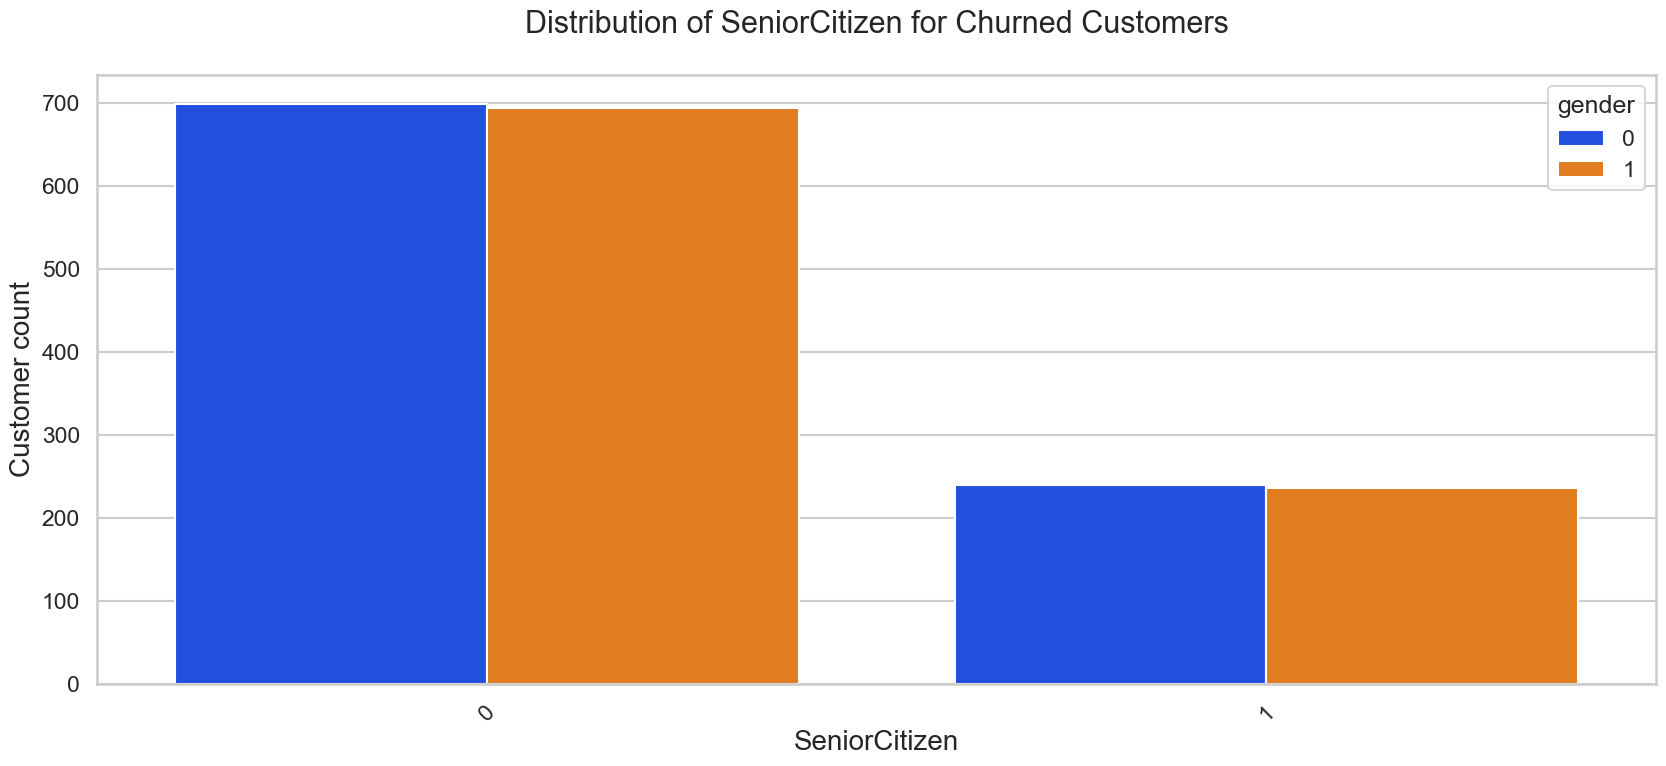

In [39]:
uniplot(new_df1_target1,col='SeniorCitizen',title='Distribution of SeniorCitizen for Churned Customers',hue='gender')

# Model training


In [40]:
X = telco_data.drop('Churn', axis=1)
y = telco_data['Churn']

print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


Churn
0    5163
1    1869
Name: count, dtype: int64
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64


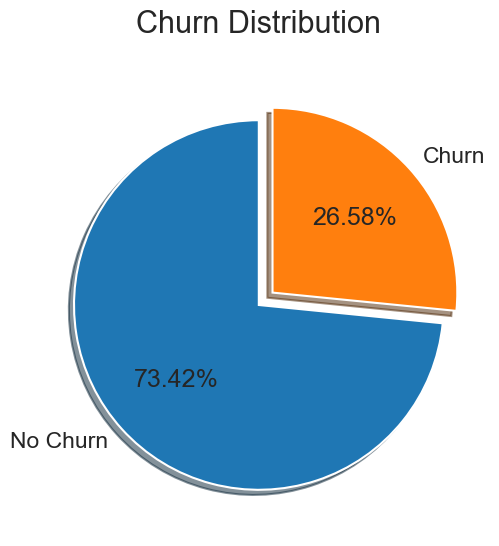

In [42]:
print(y.value_counts())

print(y.value_counts(normalize=True) * 100)

# Pie chart
plt.figure(figsize=(6, 6))

plt.pie(
    y.value_counts(),
    labels=['No Churn', 'Churn'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0, 0.1),
    shadow=True
)

plt.title('Churn Distribution')
plt.show()

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5625, 19)
Testing Data: (1407, 19)


In [49]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_test_scaled).head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,-1.00374,-0.439319,1.028312,1.529143,1.077320,0.327542,-0.995959,-1.183089,-0.916406,1.229379,-1.028168,1.383546,1.136753,1.133923,1.567119,0.824382,-0.535318,0.363738,0.984674
1,-1.00374,-0.439319,-0.972468,-0.653961,-1.041649,0.327542,1.112139,0.175326,-0.916406,1.229379,-1.028168,-0.930592,-1.120302,-1.123089,-0.830880,0.824382,-1.473959,0.450100,-0.781798
2,-1.00374,-0.439319,-0.972468,-0.653961,0.873573,0.327542,-0.995959,1.533741,0.245628,0.095730,0.106731,0.226477,0.008226,0.005417,1.567119,-1.213030,1.341965,-1.491376,-0.537223
3,-1.00374,-0.439319,-0.972468,-0.653961,-1.245396,0.327542,-0.995959,1.533741,0.245628,0.095730,0.106731,0.226477,0.008226,0.005417,-0.830880,-1.213030,1.341965,-1.473107,-0.994619
4,-1.00374,-0.439319,1.028312,-0.653961,1.566313,0.327542,1.112139,0.175326,-0.916406,1.229379,1.241630,-0.930592,1.136753,1.133923,1.567119,0.824382,-1.473959,1.333645,2.308692


In [53]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

In [52]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4130
1    4130
Name: count, dtype: int64


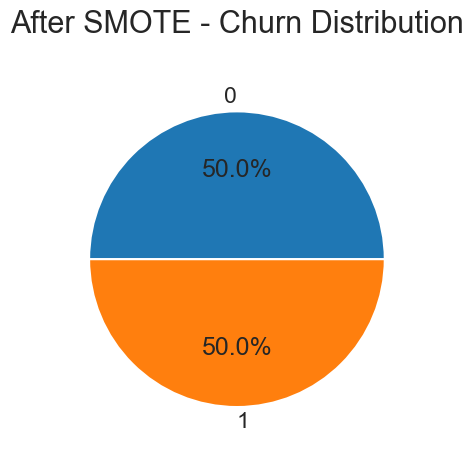

In [55]:
y_train_smote.value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.title('After SMOTE - Churn Distribution')
plt.ylabel('')
plt.show()

In [61]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=8,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric='logloss',
        random_state=42
    )
}

In [62]:
results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_smote, y_train_smote)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    # Store trained model and predictions
    trained_models[name] = model
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print(name, "Training Completed")

Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
AdaBoost Training Completed
Gradient Boosting Training Completed
XGBoost Training Completed


In [63]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
4,Gradient Boosting,0.773276,0.558635,0.700535,0.621590
3,AdaBoost,0.749112,0.518851,0.772727,0.620838
2,Random Forest,0.766169,0.546778,0.703209,0.615205
0,Logistic Regression,0.736318,0.502547,0.791444,0.614746
5,XGBoost,0.774698,0.564045,0.671123,0.612943
1,Decision Tree,0.749822,0.520992,0.729947,0.608018


In [ ]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4130
1    4130
Name: count, dtype: int64


In [68]:
for name, y_pred in predictions.items():

    print("\nMODEL:", name)

    report = classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn'],
        output_dict=True
    )

    report_df = pd.DataFrame(report).transpose()

    display(report_df.round(3))


MODEL: Logistic Regression


,precision,recall,f1-score,support
No Churn,0.905,0.716,0.800,1033.000
Churn,0.503,0.791,0.615,374.000
accuracy,0.736,0.736,0.736,0.736
macro avg,0.704,0.754,0.707,1407.000
weighted avg,0.798,0.736,0.750,1407.000



MODEL: Decision Tree


,precision,recall,f1-score,support
No Churn,0.886,0.757,0.816,1033.00
Churn,0.521,0.730,0.608,374.00
accuracy,0.750,0.750,0.750,0.75
macro avg,0.703,0.743,0.712,1407.00
weighted avg,0.789,0.750,0.761,1407.00



MODEL: Random Forest


,precision,recall,f1-score,support
No Churn,0.880,0.789,0.832,1033.000
Churn,0.547,0.703,0.615,374.000
accuracy,0.766,0.766,0.766,0.766
macro avg,0.713,0.746,0.724,1407.000
weighted avg,0.792,0.766,0.774,1407.000


... (2 outputs left out)


MODEL: Gradient Boosting


,precision,recall,f1-score,support
No Churn,0.881,0.800,0.838,1033.000
Churn,0.559,0.701,0.622,374.000
accuracy,0.773,0.773,0.773,0.773
macro avg,0.720,0.750,0.730,1407.000
weighted avg,0.795,0.773,0.781,1407.000



MODEL: XGBoost


,precision,recall,f1-score,support
No Churn,0.872,0.812,0.841,1033.000
Churn,0.564,0.671,0.613,374.000
accuracy,0.775,0.775,0.775,0.775
macro avg,0.718,0.742,0.727,1407.000
weighted avg,0.790,0.775,0.780,1407.000


In [70]:
for name, y_pred in predictions.items():
    print(name)
    print(confusion_matrix(y_test, y_pred))
    print()

Logistic Regression
[[740 293]
 [ 78 296]]

Decision Tree
[[782 251]
 [101 273]]

Random Forest
[[815 218]
 [111 263]]

AdaBoost
[[765 268]
 [ 85 289]]

Gradient Boosting
[[826 207]
 [112 262]]

XGBoost
[[839 194]
 [123 251]]



In [ ]:
gb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', GradientBoostingClassifier(random_state=42))
])

param_dist = {
    'model__n_estimators': [50, 100, 150, 200],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_depth': [3, 5, 7],
    'model__min_samples_split': [2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV F1 Score:", random_search.best_score_)

Best Parameters: {'model__n_estimators': 150, 'model__min_samples_split': 10, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best CV F1 Score: 0.6314200075036756


In [73]:
final_gb_classifier = random_search.best_estimator_

y_pred_final = final_gb_classifier.predict(X_test)

In [ ]:
print(classification_report(
    y_test,
    y_pred_final,
    target_names=['No Churn', 'Churn']
))

              precision    recall  f1-score   support

    No Churn       0.89      0.79      0.83      1033
       Churn       0.55      0.72      0.62       374

    accuracy                           0.77      1407
   macro avg       0.72      0.75      0.73      1407
weighted avg       0.80      0.77      0.78      1407



In [ ]:
cm = confusion_matrix(y_test, y_pred_final)
print(cm)

[[813 220]
 [105 269]]


In [78]:
final_results = pd.DataFrame({
    'Model': ['Tuned Gradient Boosting'],
    'Accuracy': [accuracy_score(y_test, y_pred_final)],
    'Precision': [precision_score(y_test, y_pred_final)],
    'Recall': [recall_score(y_test, y_pred_final)],
    'F1 Score': [f1_score(y_test, y_pred_final)]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Gradient Boosting,0.769012,0.550102,0.719251,0.623407


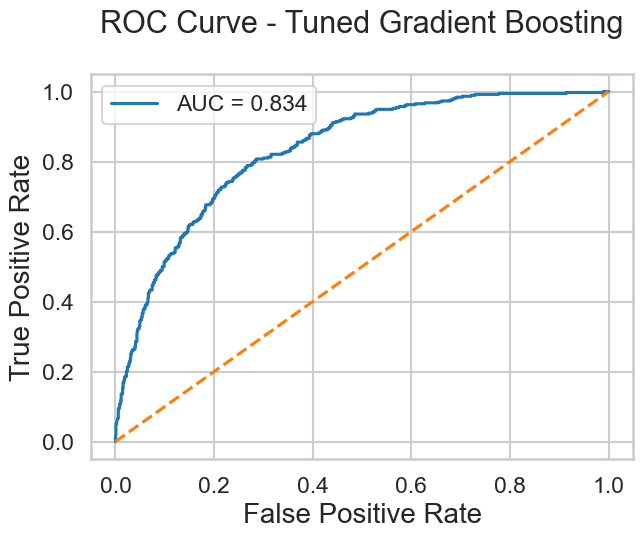

AUC Score: 0.8335697387288981


In [ ]:
y_prob = final_gb_classifier.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Gradient Boosting')
plt.legend()
plt.show()

print("AUC Score:", auc_score)

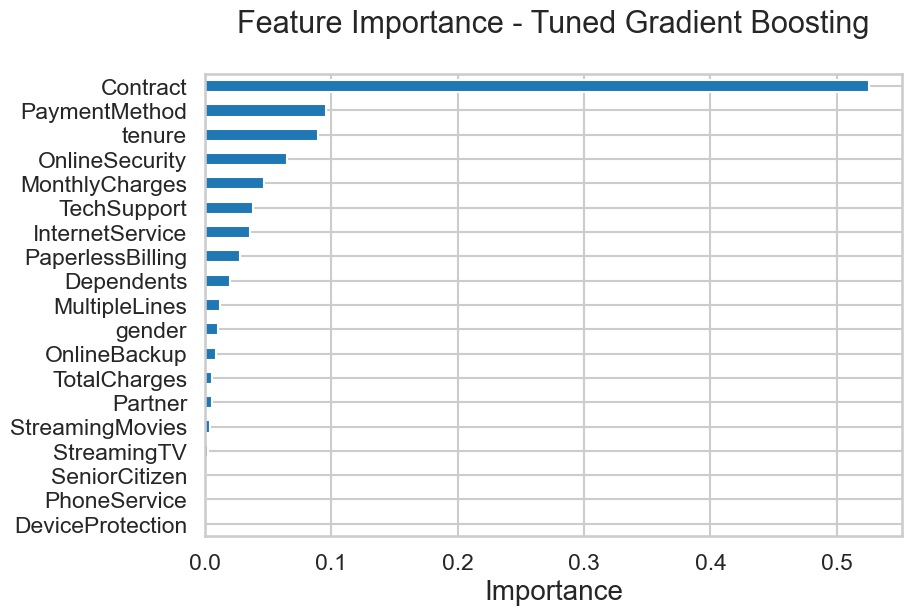

In [81]:
feature_importance = pd.Series(
    final_gb_classifier.named_steps['model'].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

feature_importance.plot(kind='barh')

plt.title('Feature Importance - Tuned Gradient Boosting')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.show()

In [82]:
import pickle

with open('final_gb_classifier.pkl', 'wb') as file:
    pickle.dump(final_gb_classifier, file)

print("Final model saved successfully!")

Final model saved successfully!
